# Phase 2 - Data splitting, preprocessing and leakage prevention
**Objective:** create reliable training, calibration and test data, and *test* with executable checks whether anything from the future reaches a model, a calibrator or a threshold. The checks can find leaks; they cannot guarantee there are none (see section 12).

This notebook answers the review of Phase 2 point by point:

| Review item | Where it is answered |
|---|---|
| 70/10/20 chronological split from the plan | section 2 (implemented) and section 9 (a full experiment on it) |
| Why our project split differs, and is the test set untouched? | sections 3-4 |
| Exact split dates, row counts and class mix | sections 2-3 |
| Duplicate checks across splits | section 5 |
| History features use only the past | section 6 (three executable tests) |
| Customer and text-template leakage | section 7 |
| Catalogue fields computed from labels | section 8 |
| Calibration and thresholds chosen without test labels | section 10 |
| Official scoring formula | section 11 |
| Reproducible pipeline | the code lives in `src/r2sorter` (`splits.py`, `features.py`, `text.py`, `model.py`); this notebook calls it |

**How to run:** keep this file in `FULL_CODE/notebooks/` of the project (it imports `../src/r2sorter`) with the five official CSVs in `FULL_CODE/data/`. Run with the project environment (`uv sync`). Total run time is about 6-8 minutes.

In [1]:
import inspect
import sys
from pathlib import Path

for candidate in (Path("../src"), Path("src")):
    if candidate.exists():
        sys.path.insert(0, str(candidate.resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold

from r2sorter.calibration import AbuseCalibrator
from r2sorter.config import load_config
from r2sorter.data import LABELS, load_all
from r2sorter.features import LABEL_HISTORY_COLUMNS, add_label_history, build_feature_table, tabular_columns
from r2sorter.model import StackModel
from r2sorter.router import break_even_thresholds, route
from r2sorter.scoring import load_official_scorer, official_score
from r2sorter.splits import assert_chronological, chronological_split, describe_splits
from r2sorter.text import TextReasonModel, normalise_reason, out_of_fold_text_probs

pd.set_option("display.max_columns", 40, "display.width", 170)
plt.rcParams.update({"figure.figsize": (8, 3.4), "axes.spines.top": False, "axes.spines.right": False})

cfg = load_config()
data = load_all(cfg)
frame = build_feature_table(data["train"], data["test"], data["products"], cfg)  # train + test in time order
labelled = frame[frame["is_train"]]
test_rows = frame[~frame["is_train"]]
ABUSIVE = LABELS.index("abusive")
print("seed:", cfg["seed"], "| labelled rows:", len(labelled), "| final-test rows (labels hidden):", len(test_rows))

seed: 42 | labelled rows: 43068 | final-test rows (labels hidden): 16932


## 1. Principles that every split below must satisfy
1. **Chronology:** training < calibration < evaluation, strictly, by `return_request_date` (verified real dates in Phase 1).
2. **The final test (July-September 2026) is never touched:** its labels do not exist, and nothing is fitted, calibrated or tuned on it.
3. **History features see only the past** and **customer-level text probabilities are out-of-fold**.
4. **Thresholds are derived from the cost matrix, not from test labels.**

## 2. The split the plan asks for: 70% train / 10% calibration / 20% test (chronological)
Implemented in `r2sorter.splits.chronological_split`: rows are cut by **date** so one calendar day is never divided between two splits.

In [2]:
plan = chronological_split(labelled["return_request_date"])
plan_table = describe_splits(labelled, plan)
assert_chronological(labelled, plan, ["train", "calibration", "test"])
print("chronology check passed: train < calibration < test")
plan_table

chronology check passed: train < calibration < test


,first_date,last_date,rows,share_of_rows,days,abusive,genuine_quality_issue,genuine_fit_issue,genuine_wrong_item
split,,,,,,,,,
train,2025-10-01,2026-04-07,30183,0.701,189,0.079,0.275,0.477,0.169
calibration,2026-04-08,2026-05-07,4388,0.102,30,0.065,0.294,0.488,0.152
test,2026-05-08,2026-06-30,8497,0.197,54,0.082,0.289,0.493,0.136


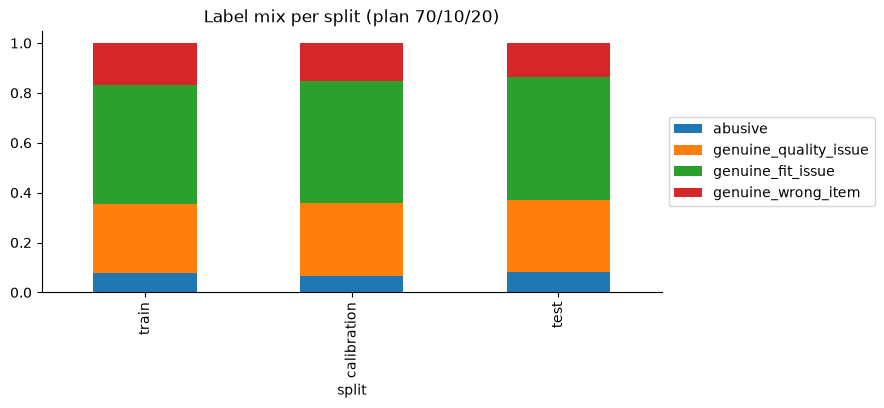

In [3]:
plan_table[list(LABELS)].plot.bar(stacked=True, title="Label mix per split (plan 70/10/20)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

## 3. The split this project actually uses, and why it differs
**What the plan split would do:** evaluate on the last 20% (about 55 days of the labelled data) after one fit.

**What the deployed system faces:** a model refreshed regularly and used on the *next* months. So we use
- a **rolling-origin** scheme: for each month from February to April, fit on everything before it and predict that month. These out-of-time predictions are used to **calibrate** the probabilities (replacing the plan's single 10% slice, which is small - about 4,300 rows and only about 330 abusive cases);
- a **May-June holdout** (the two most recent labelled months) to evaluate;
- the **hidden July-September test** as the one true final test.

This is a deliberate deviation from the plan. It keeps the plan's principle (train, then calibrate, then test, always in time order) and uses more data for calibration. Section 9 also runs the plan's exact 70/10/20 split so the two can be compared.

In [4]:
windows = []
holdout_start = pd.Timestamp(cfg["validation"]["holdout_start"])
calibration_start = pd.Timestamp(cfg["validation"]["calibration_start"])
for month_start in pd.date_range(calibration_start, holdout_start, freq="MS", inclusive="left"):
    month_end = month_start + pd.offsets.MonthBegin(1)
    windows.append(("calibration fold", month_start, month_end))
windows.append(("HOLDOUT (evaluation)", holdout_start, labelled["return_request_date"].max() + pd.Timedelta(days=1)))

rows = []
for role, start, end in windows:
    fit = labelled[labelled["return_request_date"] < start]
    predict = labelled[(labelled["return_request_date"] >= start) & (labelled["return_request_date"] < end)]
    assert fit["return_request_date"].max() < predict["return_request_date"].min(), (
        "fit data must precede the predicted window"
    )
    rows.append(
        {
            "role": role,
            "fit_first": fit["return_request_date"].min().date(),
            "fit_last": fit["return_request_date"].max().date(),
            "fit_rows": len(fit),
            "predict_first": predict["return_request_date"].min().date(),
            "predict_last": predict["return_request_date"].max().date(),
            "predict_rows": len(predict),
            "predict_abusive_%": round((predict["label"] == "abusive").mean() * 100, 1),
        }
    )
rows.append(
    {
        "role": "FINAL TEST (hidden labels)",
        "fit_first": "-",
        "fit_last": "-",
        "fit_rows": 0,
        "predict_first": test_rows["return_request_date"].min().date(),
        "predict_last": test_rows["return_request_date"].max().date(),
        "predict_rows": len(test_rows),
        "predict_abusive_%": float("nan"),
    }
)
project_table = pd.DataFrame(rows).set_index("role")
print("every fit window ends before the window it predicts: OK")
project_table

every fit window ends before the window it predicts: OK


,fit_first,fit_last,fit_rows,predict_first,predict_last,predict_rows,predict_abusive_%
role,,,,,,,
calibration fold,2025-10-01,2026-01-31,19651,2026-02-01,2026-02-28,4394,7.4
calibration fold,2025-10-01,2026-02-28,24045,2026-03-01,2026-03-31,4961,9.9
calibration fold,2025-10-01,2026-03-31,29006,2026-04-01,2026-04-30,4547,5.5
HOLDOUT (evaluation),2025-10-01,2026-04-30,33553,2026-05-01,2026-06-30,9515,8.3
FINAL TEST (hidden labels),-,-,0,2026-07-01,2026-09-30,16932,NaN


## 4. The final test set is untouched

In [5]:
assert test_rows["label"].isna().all(), "final-test labels must not exist in the data"
assert labelled["return_request_date"].max() < test_rows["return_request_date"].min()
print("final test labels are absent:", test_rows["label"].isna().all())
print(
    "labelled data ends",
    labelled["return_request_date"].max().date(),
    "| final test starts",
    test_rows["return_request_date"].min().date(),
)

# Which of the pipeline's functions are even allowed to look at final-test rows?
print(
    "\nrolling_origin_predictions filters labelled rows only ->",
    'labelled = known[known["is_train"]]'
    in inspect.getsource(__import__("r2sorter.model", fromlist=["x"]).rolling_origin_predictions),
)

final test labels are absent: True
labelled data ends 2026-06-30 | final test starts 2026-07-01

rolling_origin_predictions filters labelled rows only -> True


## 5. Duplicate and overlap checks across splits

In [6]:
for split_name, other in [("train", "calibration"), ("train", "test"), ("calibration", "test")]:
    a = set(labelled.loc[plan == split_name, "return_id"])
    b = set(labelled.loc[plan == other, "return_id"])
    print(f"return_id shared between {split_name} and {other}: {len(a & b)}")
print(
    "return_id shared between labelled data and the final test:",
    len(set(labelled["return_id"]) & set(test_rows["return_id"])),
)
print("duplicate full rows overall:", int(frame.drop(columns=["day"]).astype(str).duplicated().sum()))

event = ["customer_id", "order_id", "product_id", "size_ordered"]
events = labelled.assign(split=plan).groupby(event)["split"].agg(["size", "nunique"])
print(
    "customer+order+product+size events returned twice:",
    int((events["size"] > 1).sum()),
    "| of those spanning two splits:",
    int(((events["size"] > 1) & (events["nunique"] > 1)).sum()),
)

return_id shared between train and calibration: 0
return_id shared between train and test: 0
return_id shared between calibration and test: 0
return_id shared between labelled data and the final test: 0


duplicate full rows overall: 0
customer+order+product+size events returned twice: 6 | of those spanning two splits: 0


## 6. History features use only information from before each request
Three executable tests of `add_history_features` and `add_label_history`.

### 6a. Truncation test (the strongest one)
Rebuild every feature from a dataset in which **everything after 31 March 2026 has been deleted**. If any feature of an earlier row depended on later rows, its value would change.

In [7]:
cutoff = pd.Timestamp("2026-03-31")
short = data["train"][data["train"]["return_request_date"] <= cutoff]
cut_frame = build_feature_table(short, data["test"].iloc[:0], data["products"], cfg)
history_columns = [c for c in frame.columns if c.startswith("hist_")]
full_part = frame[frame["return_request_date"] <= cutoff].set_index("return_id")[history_columns]
cut_part = cut_frame.set_index("return_id")[history_columns].loc[full_part.index]
differences = (~np.isclose(full_part.to_numpy(float), cut_part.to_numpy(float), equal_nan=True)).sum()
print(f"{len(history_columns)} history features x {len(full_part):,} rows compared; cells that changed: {differences}")
assert differences == 0
print("PASS: deleting the future changes no earlier feature")

15 history features x 29,006 rows compared; cells that changed: 0
PASS: deleting the future changes no earlier feature


### 6b. Independent brute-force recomputation
For 400 random requests, recount from the raw rows with plain pandas (a different code path) and compare.

In [8]:
rng = np.random.default_rng(cfg["seed"])
sample = rng.choice(len(frame), 400, replace=False)
norm = frame["customer_reason"].map(normalise_reason)
mismatches = 0
for i in sample:
    row = frame.iloc[i]
    earlier = frame.iloc[:i][
        frame.iloc[:i]["customer_id"] == row["customer_id"]
    ]  # same customer, earlier in time order
    expected = {
        "hist_n_prev": len(earlier),
        "hist_returns_30d": int((earlier["day"] >= row["day"] - 30).sum()),
        "hist_returns_60d": int((earlier["day"] >= row["day"] - 60).sum()),
        "hist_returns_90d": int((earlier["day"] >= row["day"] - 90).sum()),
        "hist_same_product": int((earlier["product_id"] == row["product_id"]).sum()),
        "hist_same_text": int((norm.iloc[:i][earlier.index] == norm.iloc[i]).sum()),
    }
    mismatches += sum(row[k] != v for k, v in expected.items())
print("features compared:", 400 * 6, "| mismatches:", mismatches)
assert mismatches == 0
print("PASS: pipeline features equal an independent recount of earlier rows")

features compared: 2400 | mismatches: 0
PASS: pipeline features equal an independent recount of earlier rows


### 6c. Outcome history (`lab_*` features) cannot see the request's own label or any later label
These features carry what the retailer already *knew* about the customer's earlier outcomes, after a review delay.

In [9]:
boundary, lag, seed = pd.Timestamp("2026-05-01"), 61, cfg["seed"]
base = add_label_history(frame, boundary, lag, seed)
lab = list(LABEL_HISTORY_COLUMNS)

# (i) Shuffle every label from the boundary onwards: no feature of any row may change.
shuffled = frame.copy()
after = shuffled["is_train"] & (shuffled["return_request_date"] >= boundary)
shuffled.loc[after, "label"] = rng.permutation(shuffled.loc[after, "label"].to_numpy())
alt = add_label_history(shuffled, boundary, lag, seed)
changed = (~np.isclose(base[lab].to_numpy(float), alt[lab].to_numpy(float), equal_nan=True)).sum()
print("(i) labels from the boundary onwards shuffled -> changed cells:", changed)
assert changed == 0

# (ii) Flip the label of 500 earlier rows (one per customer): those rows' OWN features may not change.
# (A customer's LATER rows may legitimately change - they are allowed to see this outcome.)
before = frame[frame["is_train"] & (frame["return_request_date"] < boundary)]
one_per_customer = before.groupby("customer_id").sample(1, random_state=cfg["seed"])
chosen = rng.choice(one_per_customer.index, 500, replace=False)
flipped = frame.copy()
flipped.loc[chosen, "label"] = np.where(flipped.loc[chosen, "label"] == "abusive", "genuine_fit_issue", "abusive")
alt2 = add_label_history(flipped, boundary, lag, seed)
own = (~np.isclose(base.loc[chosen, lab].to_numpy(float), alt2.loc[chosen, lab].to_numpy(float), equal_nan=True)).sum()
print("(ii) own label flipped -> changed cells in those rows:", own)
assert own == 0

# (iii) Visible outcomes can never exceed the earlier returns or the labelled returns before the boundary.
assert (base["lab_n_prev"] <= base["hist_n_prev"]).all()
known_before = frame[frame["is_train"] & (frame["return_request_date"] < boundary)].groupby("customer_id").size()
late = base[base["return_request_date"] >= boundary]
assert (late["lab_n_prev"] <= late["customer_id"].map(known_before).fillna(0)).all()
print("(iii) lab_n_prev <= earlier returns, and rows after the boundary see only labels dated before it: PASS")

(i) labels from the boundary onwards shuffled -> changed cells: 0


(ii) own label flipped -> changed cells in those rows: 0
(iii) lab_n_prev <= earlier returns, and rows after the boundary see only labels dated before it: PASS


### 6d. A limitation we measure instead of hiding
The data has dates but **no time of day**. Within one calendar day, requests are ordered by `return_id`, so a request can 'see' a same-day request with a smaller ID. That is not strictly 'before'. How much does it matter?

In [10]:
same_day_prior = frame.groupby(["customer_id", "return_request_date"]).cumcount() > 0
print(
    f"requests with an earlier same-day request by the same customer: {same_day_prior.mean():.2%} ({int(same_day_prior.sum())} rows)"
)
print("Outcome (lab_*) features avoid this entirely: they use a delay of at least 1 day.")
print(
    f"abusive rate of those rows: {(labelled.loc[same_day_prior[labelled.index], 'label'] == 'abusive').mean():.3f} vs {(labelled['label'] == 'abusive').mean():.3f} overall"
)

requests with an earlier same-day request by the same customer: 1.62% (971 rows)
Outcome (lab_*) features avoid this entirely: they use a delay of at least 1 day.
abusive rate of those rows: 0.047 vs 0.078 overall


**Reading:** the pipeline passes all three tests, but 6d is a limitation, **not** something the tests can fix. Ordering same-day requests by `return_id` does not prove the earlier ID really came first, so for those rows we cannot rule out that a count feature saw a request that happened later the same day. It affects the count features of 1.62% of rows. Treat it as an open limitation, not as a leakage-free guarantee; real timestamps would remove it.

## 7. Customer and text leakage

### 7a. Text probabilities are out-of-fold *by customer*

In [11]:
source = inspect.getsource(out_of_fold_text_probs)
assert "GroupKFold" in source
pre = labelled[labelled["return_request_date"] < holdout_start]
for fold, (fit_idx, valid_idx) in enumerate(
    GroupKFold(cfg["validation"]["text_oof_folds"]).split(pre, groups=pre["customer_id"])
):
    shared = set(pre["customer_id"].iloc[fit_idx]) & set(pre["customer_id"].iloc[valid_idx])
    assert not shared, f"fold {fold} shares customers"
print(
    "customers shared between the fitting part and the predicted part of every fold: 0  (same splitter the pipeline uses)"
)

customers shared between the fitting part and the predicted part of every fold: 0  (same splitter the pipeline uses)


In [12]:
oof = out_of_fold_text_probs(
    pre["customer_reason"],
    pre["label"],
    pre["customer_id"],
    cfg["text"],
    cfg["validation"]["text_oof_folds"],
    cfg["seed"],
)
text_model = TextReasonModel(cfg["text"], cfg["seed"]).fit(pre["customer_reason"], pre["label"])
in_sample = text_model.predict_proba(pre["customer_reason"])
holdout = labelled[labelled["return_request_date"] >= holdout_start]
holdout_probs = text_model.predict_proba(holdout["customer_reason"])


def summary(probs, rows):
    truth = rows["label"].map(LABELS.index).to_numpy()
    return {
        "abusive AP": average_precision_score(truth == ABUSIVE, probs[:, ABUSIVE]),
        "4-class accuracy": float((probs.argmax(axis=1) == truth).mean()),
    }


leak_table = pd.DataFrame(
    {
        "in-sample (WRONG way: model saw these rows)": summary(in_sample, pre),
        "out-of-fold by customer (used for training)": summary(oof, pre),
        "real May-June holdout (honest reference)": summary(holdout_probs, holdout),
    }
).T.round(3)
leak_table

,abusive AP,4-class accuracy
in-sample (WRONG way: model saw these rows),0.677,0.916
out-of-fold by customer (used for training),0.126,0.876
real May-June holdout (honest reference),0.182,0.872


**Reading:** scoring the text model on rows it was trained on looks far better than reality (abusive AP 0.68, accuracy 0.92). The out-of-fold probabilities used to train the second stage behave like the honest holdout: 4-class accuracy 0.88 vs 0.87, and abusive AP 0.13 vs 0.18 (the two differ somewhat because the holdout has a different abuse rate). Neither is anywhere near the in-sample figure, which is the evidence that the customer-grouped folds block this leak.

### 7b. Do reason templates repeat across splits, and does the text model just memorise them?

In [13]:
plan_train = labelled[plan == "train"]
later = labelled[plan != "train"]
seen = set(plan_train["customer_reason"].map(normalise_reason))
is_seen = later["customer_reason"].map(normalise_reason).isin(seen)
plan_text_model = TextReasonModel(cfg["text"], cfg["seed"]).fit(plan_train["customer_reason"], plan_train["label"])
probs = plan_text_model.predict_proba(later["customer_reason"])
truth = later["label"].map(LABELS.index).to_numpy()
report = pd.DataFrame(
    {
        "rows": [int(is_seen.sum()), int((~is_seen).sum())],
        "4-class accuracy": [
            float((probs.argmax(1) == truth)[is_seen.to_numpy()].mean()),
            float((probs.argmax(1) == truth)[~is_seen.to_numpy()].mean()),
        ],
        "abusive rate": [
            float((truth == ABUSIVE)[is_seen.to_numpy()].mean()),
            float((truth == ABUSIVE)[~is_seen.to_numpy()].mean()),
        ],
    },
    index=["text seen verbatim in the training split", "text never seen"],
).round(3)
print(f"{is_seen.mean():.1%} of calibration+test reason texts appear word for word in the training split")
report

26.3% of calibration+test reason texts appear word for word in the training split


,rows,4-class accuracy,abusive rate
text seen verbatim in the training split,3383,0.866,0.084
text never seen,9502,0.880,0.074


**Reading:** about a quarter of later reason texts repeat word for word from the training split, so templates do cross the split. But accuracy on repeated texts is **not higher** than on unseen ones (0.87 vs 0.88), so the text model is not winning by memorising rows. The abusive rate differs only slightly (8.4% vs 7.4%). Template overlap therefore does not leak the label here. It is still a reason to evaluate on later months and to keep text a *supporting* signal.

### 7c. The same customers appear in several splits - this is real, not a leak

In [14]:
train_customers = set(plan_train["customer_id"])
for name in ["calibration", "test"]:
    ids = labelled.loc[plan == name, "customer_id"]
    print(f"{name:12} requests from customers already in the training split: {ids.isin(train_customers).mean():.1%}")
print(
    f"final test   requests from customers already in labelled data:   {test_rows['customer_id'].isin(set(labelled['customer_id'])).mean():.1%}"
)

calibration  requests from customers already in the training split: 69.3%
test         requests from customers already in the training split: 65.6%


final test   requests from customers already in labelled data:   73.7%


In deployment the retailer *will* see the same customers again, so splitting by customer would make validation unrealistically hard. The protection is the **point-in-time** features (section 6), not removing customers from the evaluation data. Customer-grouped folds are used only inside training, to make text probabilities honest.

## 8. Catalogue and customer fields computed from the labels?
The request that raised this mentions a field like `fit_issue_prop`. Phase 1 already scanned every column of `products.csv`, `size_charts.csv` and `customers.csv` and found no label-like names and no column with leaked predictive power. Here we check what the **model is actually given**.

In [15]:
columns = tabular_columns(base)  # `base` already has the outcome-history columns added in 6c
groups = {
    "order facts (given with the request)": [
        c
        for c in columns
        if c
        in {
            "delivery_days",
            "days_since_delivery",
            "order_value_inr",
            "item_price_inr",
            "discount_pct",
            "items_in_order",
            "customer_tenure_days",
            "prior_orders_count",
            "prior_return_rate",
        }
    ],
    "catalogue (static product facts)": [
        c
        for c in columns
        if c
        in {
            "brand",
            "fabric",
            "fit_type",
            "mrp_inr",
            "size_pos_frac",
            "price_mismatch",
            "item_share_of_order",
            "size_kind",
            "category",
            "sub_category",
        }
    ],
    "history of EARLIER requests": [c for c in columns if c.startswith("hist_")],
    "earlier OUTCOMES, after review delay": [c for c in columns if c.startswith("lab_")],
    "text evidence flags": [c for c in columns if c.startswith(("ev_", "txt_"))],
}
for name, cols in groups.items():
    print(f"{name:40} {len(cols):2d}  {cols[:6]}{' ...' if len(cols) > 6 else ''}")
assert "label" not in columns and "abusive" not in columns
assert set(c for c in columns if c.startswith("lab_")) <= set(LABEL_HISTORY_COLUMNS)
print("\nthe label itself is never a feature; outcome features exist only through add_label_history (tested in 6c)")
print("catalogue columns used:", [c for c in data["products"].columns if c in columns])

order facts (given with the request)      9  ['delivery_days', 'days_since_delivery', 'order_value_inr', 'item_price_inr', 'discount_pct', 'items_in_order'] ...
catalogue (static product facts)         10  ['size_pos_frac', 'mrp_inr', 'price_mismatch', 'item_share_of_order', 'category', 'sub_category'] ...
history of EARLIER requests              15  ['hist_n_prev', 'hist_days_since_prev', 'hist_max_text_sim', 'hist_n_similar_text', 'hist_same_product', 'hist_same_subcat_size'] ...
earlier OUTCOMES, after review delay      7  ['lab_n_prev', 'lab_n_abusive', 'lab_abuse_share', 'lab_n_fit', 'lab_n_quality', 'lab_n_wrong'] ...
text evidence flags                      22  ['ev_empty_box', 'ev_tags_intact', 'ev_tags_missing', 'ev_worn_signs', 'ev_fit_small', 'ev_fit_large'] ...

the label itself is never a feature; outcome features exist only through add_label_history (tested in 6c)
catalogue columns used: ['category', 'sub_category', 'brand', 'fabric', 'fit_type']


In [16]:
fit_counts = labelled[labelled["label"] == "genuine_fit_issue"].groupby("product_id").size()
per_product = data["products"].set_index("product_id").assign(fit_returns=fit_counts).fillna({"fit_returns": 0})
print(
    "correlation of catalogue price with a product's own fit-return count:",
    round(per_product["price_inr"].corr(per_product["fit_returns"]), 3),
)
print("products.csv holds", data["products"].shape[1], "descriptive columns and no per-product return statistics")

correlation of catalogue price with a product's own fit-return count: -0.154
products.csv holds 12 descriptive columns and no per-product return statistics


## 9. The plan's 70/10/20 split, run end to end
To see whether our different split matters, we run the plan's exact design: fit on the 70%, calibrate on the 10%, evaluate on the 20% with the **official scorer**. Outcome-history features see only labels dated before the calibration start.

In [17]:
calibration_start_plan = labelled.loc[plan == "calibration", "return_request_date"].min()
lag_plan = int((labelled["return_request_date"].max() - calibration_start_plan).days) + 1
known = add_label_history(frame, calibration_start_plan, lag_plan, cfg["seed"])
fit_rows = known[known["is_train"] & (known["return_request_date"] < calibration_start_plan)]
cal_rows = known.loc[labelled.index[plan == "calibration"]]
eval_rows = known.loc[labelled.index[plan == "test"]]
assert (
    fit_rows["return_request_date"].max()
    < cal_rows["return_request_date"].min()
    <= cal_rows["return_request_date"].max()
    < eval_rows["return_request_date"].min()
)

plan_model = StackModel(cfg).fit(fit_rows)
cal_pred = plan_model.predict(cal_rows)
eval_pred = plan_model.predict(eval_rows)
calibrator = AbuseCalibrator(cfg["calibration"]["method"]).fit(
    cal_pred["p_abuse_raw"].to_numpy(), (cal_rows["label"] == "abusive").to_numpy()
)
p_plan = calibrator.transform(eval_pred["p_abuse_raw"].to_numpy())
decisions_plan = route(p_plan, cfg)
result_plan = official_score(
    pd.DataFrame(
        {"return_id": eval_rows["return_id"], "decision": decisions_plan, "confidence": p_plan, "justification": "x"}
    ),
    eval_rows,
)
print("fit rows", len(fit_rows), "| calibration rows", len(cal_rows), "| evaluation rows", len(eval_rows))
pd.Series(decisions_plan).value_counts().to_frame("decisions on the 20% test")

fit rows 30183 | calibration rows 4388 | evaluation rows 8497


,decisions on the 20% test
auto_approve,8037
inspect,317
escalate,143


In [18]:
def headline(result):
    c, k = result["components"], result["calibration_of_confidence_as_P_abusive"]
    return {
        "savings": c["savings"],
        "fairness": c["fairness_score"],
        "primary (no size-chart part)": result["primary_score"],
        "abusive average precision": k["average_precision"],
        "Brier": k["brier"],
        "ECE": k["ece_10_bins"],
        "genuine customers escalated": result["abuse_detection"]["genuine_escalated"],
    }


comparison = {"plan split: 70/10/20 (this section)": headline(result_plan)}
reports = Path("../reports/validation.json")
if reports.exists():
    import json

    saved = json.loads(reports.read_text())
    comparison["project split: May-June holdout (reports/validation.json)"] = headline(saved)
pd.DataFrame(comparison).T.round(4)

,savings,fairness,primary (no size-chart part),abusive average precision,Brier,ECE,genuine customers escalated
plan split: 70/10/20 (this section),0.3106,0.5964,0.3367,0.7531,0.0343,0.0129,7.0
project split: May-June holdout (reports/validation.json),0.3853,0.5587,0.3814,0.7749,0.0325,0.0051,2.0


**Reading:** both designs give clearly positive savings and no sign of leakage, but the plan's single 10% calibration slice does worse: savings 0.31 vs 0.39, calibration error 0.013 vs 0.005, and 7 vs 2 honest customers escalated. The likely cause is that the plan's 10% slice is small (4,388 rows) and covers one low-abuse stretch (6.5% abusive), so the calibrator fits less well; the project's three rolling months give it 13,902 out-of-time rows. The two rows also cover different evaluation periods, so the gap is not a pure like-for-like comparison. Conclusion: the deviation is documented and justified, not harmful.

## 10. Calibration and thresholds never use test labels

In [19]:
print("break_even_thresholds signature:", inspect.signature(break_even_thresholds))
print("-> it receives only the cost matrix, no labels or predictions:", break_even_thresholds(cfg))
print("route() signature:", inspect.signature(route), "(probabilities and costs only)")

calibration_file = Path("../reports/calibration_out_of_time.csv")
if calibration_file.exists():
    used = pd.read_csv(calibration_file, index_col="row")
    dates = frame.loc[used.index, "return_request_date"]
    print(
        f"\ncalibrator of the project split was fitted on {len(used):,} out-of-time predictions dated {dates.min().date()} to {dates.max().date()}"
    )
    assert dates.max() < holdout_start and dates.min() >= calibration_start
    print("PASS: every calibration row is earlier than the May-June holdout")
else:
    print("\n(reports/calibration_out_of_time.csv not found - run `python main.py validate` to produce it)")

break_even_thresholds signature: (cfg: 'dict[str, Any]') -> 'dict[str, float]'
-> it receives only the cost matrix, no labels or predictions: {'approve_to_inspect': 0.4166666666666667, 'inspect_to_escalate': 0.9693877551020408}
route() signature: (p_abuse: 'np.ndarray', cfg: 'dict[str, Any]') -> 'np.ndarray' (probabilities and costs only)

calibrator of the project split was fitted on 13,902 out-of-time predictions dated 2026-02-01 to 2026-04-30
PASS: every calibration row is earlier than the May-June holdout


**Honest note on how the May-June holdout was used.** Thresholds are fixed by the cost matrix (no tuning). However, while building the model I compared a few hyperparameter and feature variants on the May-June holdout, so that holdout behaves as a **validation set**: its scores can be slightly optimistic. The unbiased estimates are (a) the plan-split result in section 9, where the model was not tuned, and (b) the hidden July-September test. We therefore never report the holdout as the final score.

## 11. The scoring formula (resolved against the official evaluator)

In [20]:
official = load_official_scorer()
print("official cost matrix:", official.COST)
print(
    "official score weights: savings",
    official.W_SAVINGS,
    "| fairness",
    official.W_FAIRNESS,
    "| size chart",
    official.W_SIZE_CHART,
)
assert official.COST["genuine"]["escalate"] == 10.0 and official.COST["abusive"]["auto_approve"] == 1.0
assert official.COST["genuine"]["inspect"] == 0.5 and official.COST["abusive"]["inspect"] == 0.3
assert cfg["costs"] == official.COST, "project config must equal the official matrix"
print("project config.yaml costs equal the official matrix: PASS")

official cost matrix: {'genuine': {'auto_approve': 0.0, 'inspect': 0.5, 'escalate': 10.0}, 'abusive': {'auto_approve': 1.0, 'inspect': 0.3, 'escalate': 0.0}}
official score weights: savings 0.7 | fairness 0.2 | size chart 0.1
project config.yaml costs equal the official matrix: PASS


| formula | verdict |
|---|---|
| `10 x MissedFraud + 1 x WrongBlock + 0.2 x UnnecessaryInspect` (pasted plan) | reversed direction - **rejected** |
| `10 x WrongBlock + 1 x MissedFraud + 0.2 x UnnecessaryInspect` (review note) | right direction, but the inspect cost is 0.5 (genuine) / 0.3 (abusive), not 0.2 |
| official matrix: wrong block 10, missed fraud 1, unnecessary inspect 0.5, inspect of an abuser 0.3 | **the benchmark, enforced by an assertion above** |

## 12. Caveats that stay attached to every Phase 2 result
**1. Same-day ordering.** The data has dates but no time of day. 1.62% of requests have an earlier same-day request from the same customer (section 6d). Ordering them by `return_id` does not prove the earlier request actually happened first. This is a limitation, not a fully leakage-free guarantee.

**2. Holdout tuning.** The May-June holdout was used to compare model and feature variants (section 10), so its results may be optimistic. The untouched July-September test stays separate for the final evaluation; the plan-split result (section 9) is a second, untuned estimate.

**3. Outcome-history availability.** The delayed-label-history design (`lab_*` features) assumes review outcomes become known 1-92 days after a request. In a real retailer workflow, outcomes exist only for requests that were inspected or resolved, and may arrive later or in a different pattern. If that assumption fails, these features would be sparser than in our experiments and performance would be lower.

**What the passing tests do and do not show.** They show that the implemented features do not depend on later rows (truncation test), that they match an independent recount, and that outcome features ignore the request's own and later labels. They do not show that the dataset itself was generated without leakage, or that production data would behave the same way.

## 13. Phase 2 verdict
| Requirement | Evidence | Status |
|---|---|---|
| Chronological train / calibration / test | sections 2-4, assertions | done |
| 70/10/20 split from the plan | section 2, run end to end in section 9 | done |
| Deviation documented and test untouched | sections 3-4 | done |
| Class mix and dates per split | sections 2-3 | done |
| Duplicates across splits | section 5 | done |
| History features past-only | section 6 (three tests plus one measured limitation) | tested; same-day ordering remains a limitation |
| Customer-grouped text OOF; template leakage | section 7 | done |
| Catalogue fields not label-derived | section 8 and Phase 1 | done |
| Calibration and thresholds without test labels | section 10 | done |
| Holdout tuning disclosed | sections 10 and 12 | done, results treated as optimistic |
| Official cost formula enforced | section 11 | done |
| Reproducible pipeline | `src/r2sorter/splits.py` + tests, `features.py`, `text.py`, `model.py` | done |

**Status: Phase 2 is complete with the three caveats in section 12.** It is validated to the extent the tests above can show, not proven leakage-free.

**Next:** Phase 3 - feature engineering.